In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Caminho direto para o teu ficheiro CSV
file_path = '../data/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv'

# 2. Carregar o dataset
print("A carregar o dataset... Aguarde um momento.")
df = pd.read_csv(file_path)

# 3. Limpar espaços nos nomes das colunas
df.columns = df.columns.str.strip()

# 4. Mostrar confirmação e dimensões
print("\n✅ Dataset carregado com sucesso!")
print(f"Total de Linhas: {df.shape[0]}")
print(f"Total de Colunas: {df.shape[1]}")

# Visualizar as primeiras 5 linhas
df.head()

Matplotlib is building the font cache; this may take a moment.


A carregar o dataset... Aguarde um momento.


FileNotFoundError: [Errno 2] No such file or directory: '../data/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv'

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Testar caminhos para encontrar o ficheiro independentemente de onde o VS Code está a executar
possible_paths = [
    'data/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv',
    '../data/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv',
    r'C:\Users\Guilh\OneDrive\Ambiente de Trabalho\Projetos_IAAC\IAAC_Grupo2\data\Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv'
]

file_path = None
for path in possible_paths:
    if os.path.exists(path):
        file_path = path
        break

if file_path:
    print(f"A carregar o dataset a partir de: {file_path}")
    df = pd.read_csv(file_path)
    
    # Remover espaços extras dos nomes das colunas (ex: ' Label' -> 'Label')
    df.columns = df.columns.str.strip()
    
    print("\n✅ Dataset carregado com sucesso!")
    print(f"Total de Linhas: {df.shape[0]}")
    print(f"Total de Colunas: {df.shape[1]}")
else:
    print("❌ Ficheiro não encontrado. Confirma se o ficheiro está na pasta 'data'.")

# Mostrar as primeiras linhas do dataset
df.head()

A carregar o dataset a partir de: data/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv

✅ Dataset carregado com sucesso!
Total de Linhas: 225745
Total de Colunas: 85


,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,192.168.10.5-104.16.207.165-54865-443-6,104.16.207.165,443,192.168.10.5,54865,6,7/7/2017 3:30,3,2,0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,192.168.10.5-104.16.28.216-55054-80-6,104.16.28.216,80,192.168.10.5,55054,6,7/7/2017 3:30,109,1,1,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,192.168.10.5-104.16.28.216-55055-80-6,104.16.28.216,80,192.168.10.5,55055,6,7/7/2017 3:30,52,1,1,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,192.168.10.16-104.17.241.25-46236-443-6,104.17.241.25,443,192.168.10.16,46236,6,7/7/2017 3:30,34,1,1,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,192.168.10.5-104.19.196.102-54863-443-6,104.19.196.102,443,192.168.10.5,54863,6,7/7/2017 3:30,3,2,0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [3]:
# 1. Substituir valores infinitos (Inf e -Inf) por NaN
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# 2. Verificar colunas com valores em falta
null_counts = df.isnull().sum()
null_cols = null_counts[null_counts > 0]

print("--- Colunas com valores nulos ou infinitos ---")
if not null_cols.empty:
    print(null_cols)
else:
    print("Nenhum valor em falta encontrado.")

--- Colunas com valores nulos ou infinitos ---
Flow Bytes/s      34
Flow Packets/s    34
dtype: int64


--- Contagem de Registos por Classe ---
Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64

--- Proporção Percentual (%) ---
Label
DDoS      56.71
BENIGN    43.29
Name: proportion, dtype: float64


C:\Users\Guilh\AppData\Local\Temp\ipykernel_21724\3828642153.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='Label', palette='viridis', order=df['Label'].value_counts().index)


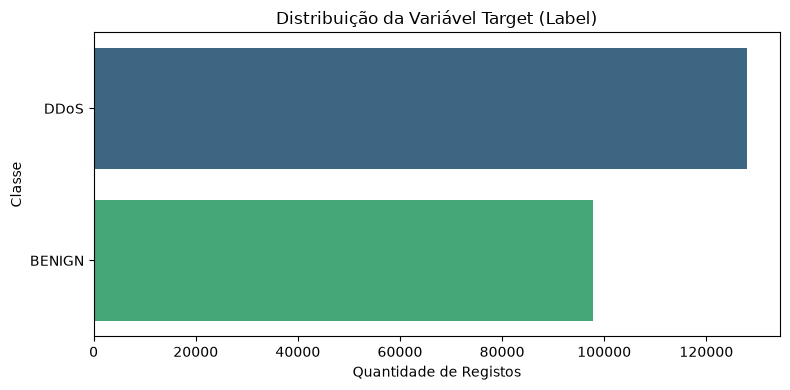

In [4]:
# 1. Contagem absoluta e percentagem das classes
print("--- Contagem de Registos por Classe ---")
print(df['Label'].value_counts())

print("\n--- Proporção Percentual (%) ---")
print((df['Label'].value_counts(normalize=True) * 100).round(2))

# 2. Gráfico da distribuição do tráfego
plt.figure(figsize=(8, 4))
sns.countplot(data=df, y='Label', palette='viridis', order=df['Label'].value_counts().index)
plt.title('Distribuição da Variável Target (Label)')
plt.xlabel('Quantidade de Registos')
plt.ylabel('Classe')
plt.tight_layout()
plt.show()

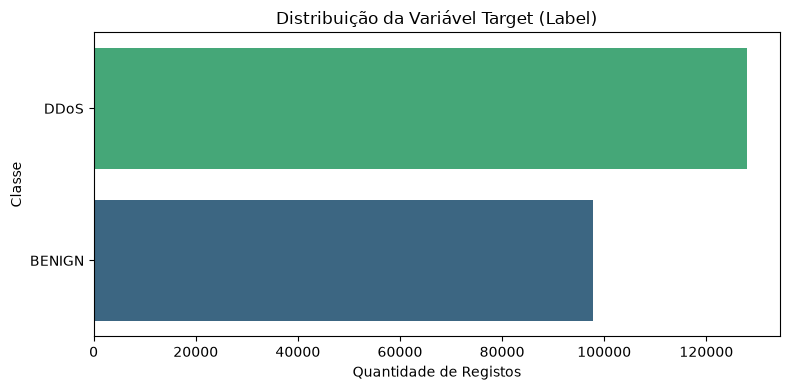

In [5]:
plt.figure(figsize=(8, 4))
sns.countplot(
    data=df, 
    y='Label', 
    hue='Label', 
    palette='viridis', 
    legend=False, 
    order=df['Label'].value_counts().index
)
plt.title('Distribuição da Variável Target (Label)')
plt.xlabel('Quantidade de Registos')
plt.ylabel('Classe')
plt.tight_layout()
plt.show()

In [6]:
# Listar todas as colunas e respetivos tipos de dados
print("--- Informação sobre Colunas e Tipos de Dados ---")
df.info(verbose=True, show_counts=True)

# Identificar colunas de texto / identificadores
text_cols = df.select_dtypes(include=['object']).columns.tolist()
print("\n--- Colunas do tipo Texto / Objeto ---")
print(text_cols)

--- Informação sobre Colunas e Tipos de Dados ---
<class 'pandas.DataFrame'>
RangeIndex: 225745 entries, 0 to 225744
Data columns (total 85 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Flow ID                      225745 non-null  str    
 1   Source IP                    225745 non-null  str    
 2   Source Port                  225745 non-null  int64  
 3   Destination IP               225745 non-null  str    
 4   Destination Port             225745 non-null  int64  
 5   Protocol                     225745 non-null  int64  
 6   Timestamp                    225745 non-null  str    
 7   Flow Duration                225745 non-null  int64  
 8   Total Fwd Packets            225745 non-null  int64  
 9   Total Backward Packets       225745 non-null  int64  
 10  Total Length of Fwd Packets  225745 non-null  int64  
 11  Total Length of Bwd Packets  225745 non-null  int64  
 12  Fwd Packet Length M

C:\Users\Guilh\AppData\Local\Temp\ipykernel_21724\4015290839.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_cols = df.select_dtypes(include=['object']).columns.tolist()


In [7]:
# Versão sem avisos para Pandas 2/3
text_cols = df.select_dtypes(include=['object', 'string']).columns.tolist()
print(text_cols)

['Flow ID', 'Source IP', 'Destination IP', 'Timestamp', 'Label']


In [8]:
# 1. Definir e remover colunas de identificação de rede
cols_to_drop = ['Flow ID', 'Source IP', 'Destination IP', 'Timestamp']
existing_cols_to_drop = [col for col in cols_to_drop if col in df.columns]

df_clean = df.drop(columns=existing_cols_to_drop)

# 2. Remover linhas com valores nulos (resultantes da conversão de Inf -> NaN)
df_clean = df_clean.dropna()

# 3. Remover registos duplicados
rows_before = len(df_clean)
df_clean = df_clean.drop_duplicates()
duplicates_removed = rows_before - len(df_clean)

print("✅ Limpeza e filtragem concluídas com sucesso!")
print(f"• Colunas de metadados removidas: {existing_cols_to_drop}")
print(f"• Registos duplicados removidos: {duplicates_removed}")
print(f"• Dimensão final do dataset: {df_clean.shape[0]} linhas e {df_clean.shape[1]} colunas")

✅ Limpeza e filtragem concluídas com sucesso!
• Colunas de metadados removidas: ['Flow ID', 'Source IP', 'Destination IP', 'Timestamp']
• Registos duplicados removidos: 126
• Dimensão final do dataset: 225585 linhas e 81 colunas
